# EDA 3 — Images and localizers

This notebook looks at the images themselves, after the preprocessing in `src/data.py`:
every series is a uint8 volume of 160 × 192 × 192 voxels of 1 mm, with the same axes for all scans
(z: top → bottom, y: front → back, x: patient's right → left).

The cached volumes of all 4,348 series are the Kaggle dataset `ahmetcan0/group11-volumes` (about 8 GB).
Here we use its two tables and only a few volumes, downloaded into `data/volumes_sample/`:

```bash
kaggle datasets download ahmetcan0/group11-volumes -f volumes_meta.csv -p data/volumes_sample
kaggle datasets download ahmetcan0/group11-volumes -f localizers_vox.csv -p data/volumes_sample
kaggle datasets download ahmetcan0/group11-volumes -f volumes_<i>/volumes/<SeriesInstanceUID>.npz -p data/volumes_sample/volumes
```

Questions:
1. Did preprocessing work for all series?
2. What do the scans of each modality look like, and where are the aneurysms?
3. What do the MIPs used by baseline B2 show, and why does B2 work worse on MRI?
4. Are the localizer points where we expect them in the head?

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
from src.data import VOLUME_SHAPE, load_volume, make_mips, volume_paths
from src.utils import ID_COL, TARGET_COL

SAMPLE = ROOT / "data" / "volumes_sample"
train = pd.read_csv(ROOT / "data" / "raw" / "train.csv")
vmeta = pd.read_csv(SAMPLE / "volumes_meta.csv")
loc = pd.read_csv(SAMPLE / "localizers_vox.csv")
paths = volume_paths(SAMPLE / "volumes")
modality_of = train.set_index(ID_COL)["Modality"]

MODALITIES = ["CTA", "MRA", "MRI T2", "MRI T1post"]
BLUE, ORANGE, AQUA, GRAY = "#2a78d6", "#eb6834", "#1baf7a", "#52514e"
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": GRAY, "axes.labelcolor": GRAY, "xtick.color": GRAY, "ytick.color": GRAY,
})
print(f"{len(paths)} sample volumes in {SAMPLE}")

5 sample volumes in C:\VsCode\GROUP11_CENG313\data\volumes_sample


## 1. Preprocessing of all series

`volumes_meta.csv` has one row per series, written by `src/data.py` on Kaggle.

In [2]:
d = train[[ID_COL, "Modality", TARGET_COL]].merge(vmeta, on=ID_COL, how="left")
print("Series:", len(d), "| errors:", d["error"].notna().sum() if "error" in d else 0)
print(f"Time per series: median {d['seconds'].median():.1f} s, max {d['seconds'].max():.0f} s")

print("\nScan plane before reorientation (all are turned to axial):")
print(pd.crosstab(d["Modality"], d["plane"]).loc[MODALITIES].to_string())

print("\nRescale applied (only when no raw pixel value is negative):")
print(pd.crosstab(d["Modality"], d["rescaled"]).loc[MODALITIES].to_string())

print("\nSeries with dropped slices (other image size or same position):",
      (d["n_dropped_slices"] > 0).sum())

Series: 4348 | errors: 0
Time per series: median 10.2 s, max 65 s

Scan plane before reorientation (all are turned to axial):
plane       axial  coronal  sagittal
Modality                            
CTA          1794        6         8
MRA          1239       12         1
MRI T2        903       43        37
MRI T1post    258       27        20

Rescale applied (only when no raw pixel value is negative):
rescaled    False  True 
Modality                
CTA          1808      0
MRA            18   1234
MRI T2         18    965
MRI T1post      1    304

Series with dropped slices (other image size or same position): 2


## 2. Localizer points in the cropped box

`localizers_vox.csv` has every localizer point of `train_localizers.csv`, moved to the coordinates (z, y, x) of the cached volume.

In [3]:
print("Localizer points:", len(loc), "| inside the box:", loc["inside"].sum())
print("\nDepth z of the aneurysms below the top of the box (mm), per modality:")
loc_mod = loc[ID_COL].map(modality_of).rename("Modality")
print(loc.groupby(loc_mod)["z"].describe(percentiles=[0.05, 0.5, 0.95]).loc[MODALITIES].round(1).to_string())
print("Points deeper than 140 mm:", loc.loc[loc["z"] > 140, "location"].value_counts().to_dict())

side = np.where(loc["location"].str.startswith("Left"), "Left",
                np.where(loc["location"].str.startswith("Right"), "Right", "Midline"))
print("\nx position (0 = patient's right edge of the box, 191 = left edge):")
print(loc.groupby(side)["x"].describe()[["count", "mean", "min", "max"]].round(1).to_string())

Localizer points: 2254 | inside the box: 2254

Depth z of the aneurysms below the top of the box (mm), per modality:
             count  mean   std  min    5%   50%    95%    max
Modality                                                     
CTA         1220.0  90.1  22.5  5.0  43.0  95.7  117.0  154.5
MRA          661.0  48.0  14.5  1.8  27.1  47.4   72.2  120.0
MRI T2       280.0  87.1  19.1  4.0  43.3  90.5  109.2  135.0
MRI T1post    93.0  96.3  17.9  4.0  75.0  96.0  122.6  149.0
Points deeper than 140 mm: {'Other Posterior Circulation': 5}

x position (0 = patient's right edge of the box, 191 = left edge):
         count   mean   min    max
Left     778.0  111.5  71.5  155.4
Midline  608.0   95.7  56.9  125.0
Right    868.0   78.6  30.8  132.4


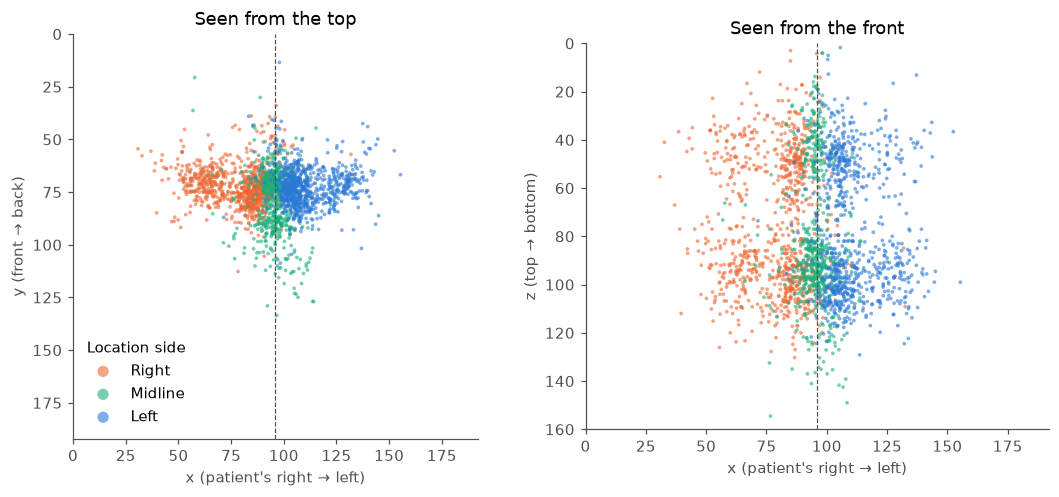

In [4]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4.6))
for name, color in [("Right", ORANGE), ("Midline", AQUA), ("Left", BLUE)]:
    pts = loc[side == name]
    ax1.scatter(pts["x"], pts["y"], s=6, color=color, alpha=0.6, label=name, edgecolors="none")
    ax2.scatter(pts["x"], pts["z"], s=6, color=color, alpha=0.6, label=name, edgecolors="none")
for ax, ylabel, ymax, title in [(ax1, "y (front → back)", VOLUME_SHAPE[1], "Seen from the top"),
                                (ax2, "z (top → bottom)", VOLUME_SHAPE[0], "Seen from the front")]:
    ax.set_xlim(0, VOLUME_SHAPE[2]); ax.set_ylim(ymax, 0); ax.set_aspect("equal")
    ax.set_xlabel("x (patient's right → left)"); ax.set_ylabel(ylabel); ax.set_title(title)
    ax.axvline(VOLUME_SHAPE[2] / 2, color=GRAY, lw=0.8, ls="--")
ax1.legend(title="Location side", frameon=False, markerscale=3)
plt.tight_layout()
plt.show()

- **Seen from the top**, the points form a small cluster in the middle of the head: the circle of Willis,
  where the large brain arteries meet.
- Points labelled *Left* are on the patient's left (x > 96), *Right* on the right, and midline arteries in the middle,
  so the reorientation and the localizer conversion agree with the labels.
- **Seen from the front**, there are two groups in z: around 47 mm for MRA and around 90 mm for the other modalities.
  The box starts at the top of the head, but an MRA scan covers only about 100 mm around the arteries (EDA 2),
  so for MRA the top of the box is the top of the scan, not of the head. The same artery is therefore at a different depth
  depending on the modality.
- The deepest points (> 140 mm) are *Other Posterior Circulation*, arteries lower in the back of the head. They are still inside the box.

## 3. One aneurysm per modality

For one positive series of each modality: the three slices through the localizer point (circle).

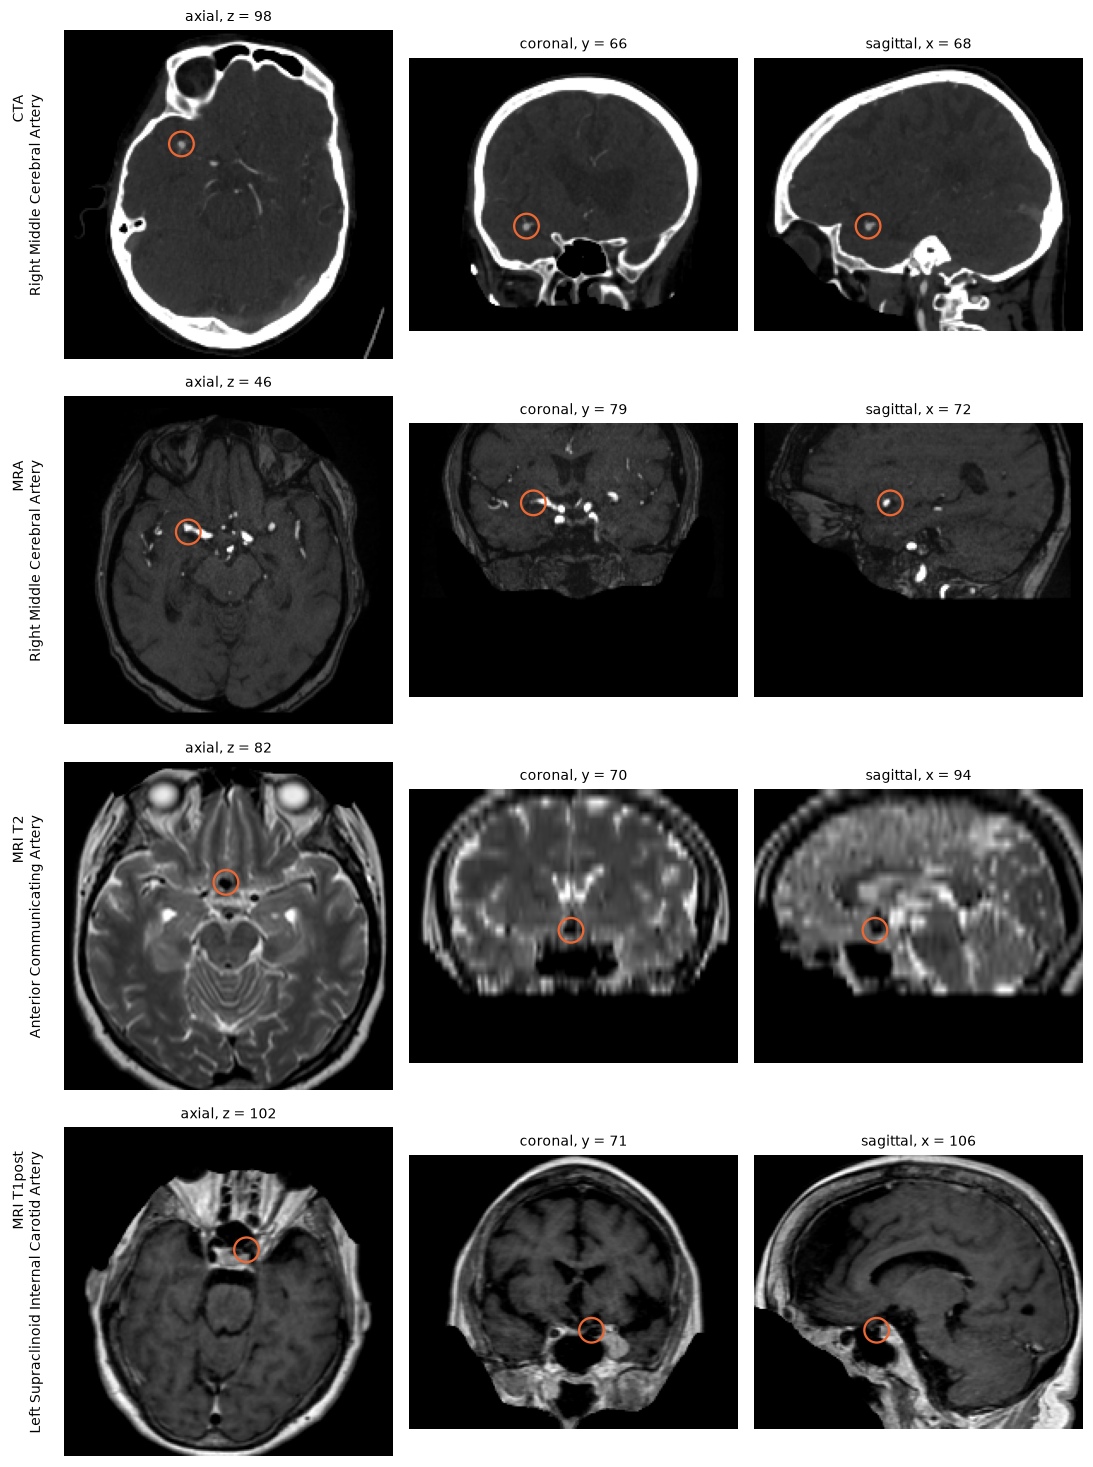

In [5]:
one_point = loc.groupby(ID_COL).filter(lambda g: len(g) == 1).set_index(ID_COL)
examples = {modality_of[uid]: uid for uid in paths if uid in one_point.index}
examples = {m: examples[m] for m in MODALITIES if m in examples}
NEGATIVE_CTA = next(uid for uid in paths if uid not in one_point.index and modality_of[uid] == "CTA")


def point_of(uid):
    p = one_point.loc[uid]
    return int(round(p["z"])), int(round(p["y"])), int(round(p["x"])), p["location"]


def mark(ax, x, y):
    ax.scatter([x], [y], s=260, facecolors="none", edgecolors=ORANGE, linewidths=1.5)


fig, axes = plt.subplots(len(examples), 3, figsize=(10, 3.4 * len(examples)))
for row, (modality, uid) in zip(axes, examples.items()):
    v = load_volume(paths[uid])
    z, y, x, location = point_of(uid)
    for ax, img, (px, py), title in [
        (row[0], v[z], (x, y), f"axial, z = {z}"),
        (row[1], v[:, y], (x, z), f"coronal, y = {y}"),
        (row[2], v[:, :, x], (y, z), f"sagittal, x = {x}"),
    ]:
        ax.imshow(img, cmap="gray", vmin=0, vmax=255)
        mark(ax, px, py)
        ax.set_title(title, fontsize=9)
        ax.axis("off")
    row[0].text(-12, VOLUME_SHAPE[1] / 2, f"{modality}\n{location}", rotation=90, ha="right", va="center", fontsize=9)
plt.tight_layout()
plt.show()

- **CTA** and **MRA** are made to show vessels: arteries are bright. On CTA the skull is also bright (it is above the 700 HU window).
  The MRA volume is empty (black) below about 100 mm, because the scan itself ends there.
- **MRI T2** shows fluid as bright: the vessels are dark lines in the bright fluid around the brain.
  Its slices are 5 mm thick, so the coronal and sagittal views are blurry along z.
- **MRI T1post** (with contrast) shows vessels and fat; the aneurysm is visible but with less contrast.

## 4. MIPs (input of baseline B2)

A maximum intensity projection keeps the brightest voxel along each line of sight. B2 uses MIPs from the top,
the front and the side (`src.data.make_mips`, channel 0 below). On CT, bone is removed first.

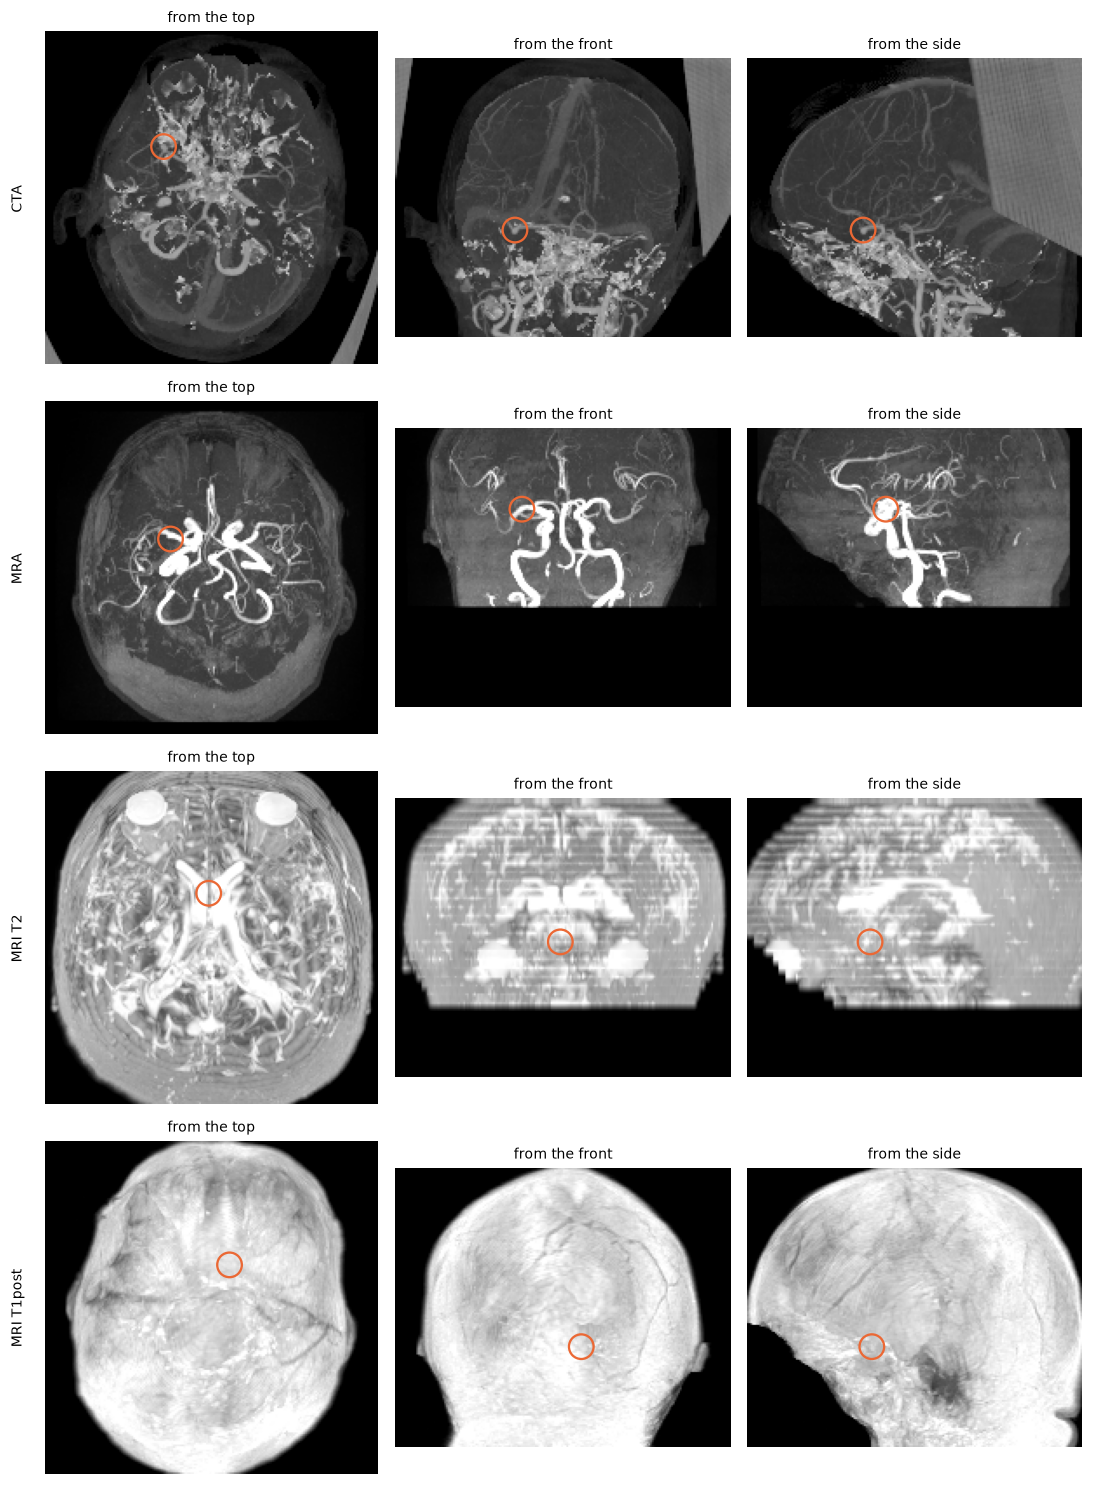

In [6]:
fig, axes = plt.subplots(len(examples), 3, figsize=(10, 3.4 * len(examples)))
for row, (modality, uid) in zip(axes, examples.items()):
    views = make_mips(load_volume(paths[uid]), is_ct=modality == "CTA")
    z, y, x, location = point_of(uid)
    for ax, view, (px, py), title in zip(row, views, [(x, y), (x, z), (y, z)], ["from the top", "from the front", "from the side"]):
        ax.imshow(view[0], cmap="gray", vmin=0, vmax=255)
        mark(ax, px, py)
        ax.set_title(title, fontsize=9)
        ax.axis("off")
    row[0].text(-12, VOLUME_SHAPE[1] / 2, modality, rotation=90, ha="right", va="center", fontsize=9)
plt.tight_layout()
plt.show()

On **CTA** and **MRA** the MIP shows the vessel tree, and the aneurysm sits on it
(on CTA, the diagonal bands at the edge are the scanner table).
On **MRI T2** the MIP shows the bright fluid, not the vessels, and on **MRI T1post** bright fat and scalp cover the brain.
This matches the B2 scores per modality: CTA 0.668 and MRA 0.647, but MRI T2 0.570 and MRI T1post 0.624.
For MRI, a 3D model on the volume itself (Assignment 2) should do better than a projection.

## 5. Why bone is removed on CT

The same negative CTA, MIP from the top without and with bone removal.

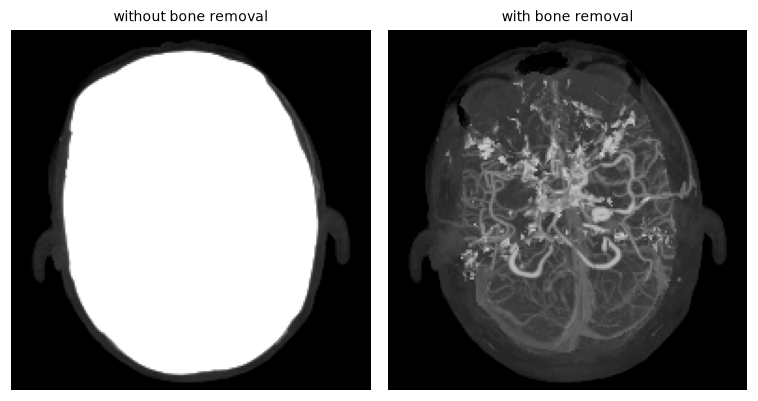

Voxels at 255 (>= 700 HU, bone): 6.3%


In [7]:
v = load_volume(paths[NEGATIVE_CTA])
fig, axes = plt.subplots(1, 2, figsize=(7, 3.6))
for ax, is_ct, title in [(axes[0], False, "without bone removal"), (axes[1], True, "with bone removal")]:
    ax.imshow(make_mips(v, is_ct=is_ct)[0][0], cmap="gray", vmin=0, vmax=255)
    ax.set_title(title, fontsize=9)
    ax.axis("off")
plt.tight_layout()
plt.show()
print(f"Voxels at 255 (>= 700 HU, bone): {(v == 255).mean():.1%}")

Without bone removal, the skull is the brightest structure on every line of sight and hides the vessels.

## 6. Findings

**Preprocessing**
- All 4,348 series were preprocessed without errors. 201 series were scanned coronal or sagittal and turned to axial,
  most of them MRI (80 MRI T2, 47 MRI T1post).
- The rescale was skipped for every CT: the pixels are already in HU. This confirms the rescale trap found in EDA 2.
- All 2,254 localizer points are inside the 160 × 192 × 192 mm box.

**Localizers**
- The aneurysms are in a small region in the middle of the head: the circle of Willis.
  Their depth in the box depends on the modality (median 47 mm for MRA, about 90 mm for the others),
  because MRA scans start lower than the top of the head.
- Left / right / midline labels match the x position of the points, so the volume axes and the localizer conversion are right.

**Images and MIPs**
- CTA and MRA show the vessels as bright, and their MIPs show the vessel tree with the aneurysm on it.
- MRI T2 shows fluid as bright and has 5 mm slices; MRI T1post shows fat and scalp as bright.
  Their MIPs do not show the vessels, which explains why B2 is weak on MRI T2 (0.570) and MRI T1post.
- On CT, the skull must be removed before a MIP, otherwise it hides the vessels.

**For Assignment 2**
- Since all aneurysms are in a small central region, the model can focus on a crop around the circle of Willis
  (Option B), which allows a finer resolution than 1 mm. The crop must be found in each scan (for example from the vessels),
  because its depth in the box differs between modalities.
- MRI needs a model that looks at the volume (3D), not at a projection.